<a href="https://colab.research.google.com/github/Hansulich/ml-portfolio/blob/main/04_ann_backpropagation/ann_backpropagation_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch     1 | MSE: 5.695723 | MAPE: 351.04%
Epoch  1000 | MSE: 0.002465 | MAPE: 12.71%


Epoch  2000 | MSE: 0.001817 | MAPE: 9.37%
Epoch  3000 | MSE: 0.001428 | MAPE: 7.49%


Epoch  4000 | MSE: 0.001173 | MAPE: 6.52%
Epoch  5000 | MSE: 0.000997 | MAPE: 5.98%
Epoch  6000 | MSE: 0.000870 | MAPE: 5.70%


Epoch  7000 | MSE: 0.000776 | MAPE: 5.54%
Epoch  8000 | MSE: 0.000705 | MAPE: 5.43%
Epoch  9000 | MSE: 0.000650 | MAPE: 5.36%


Epoch 10000 | MSE: 0.000606 | MAPE: 5.31%

실제값 vs 예측값 (처음 5개 샘플)
x1=0.549, x2=0.593 | y=1.8763 | y_hat=1.9017
x1=0.715, x2=0.010 | y=0.4606 | y_hat=0.4796
x1=0.603, x2=0.476 | y=1.6330 | y_hat=1.6444
x1=0.545, x2=0.709 | y=2.2161 | y_hat=2.2531
x1=0.424, x2=0.044 | y=-0.0208 | y_hat=-0.0155


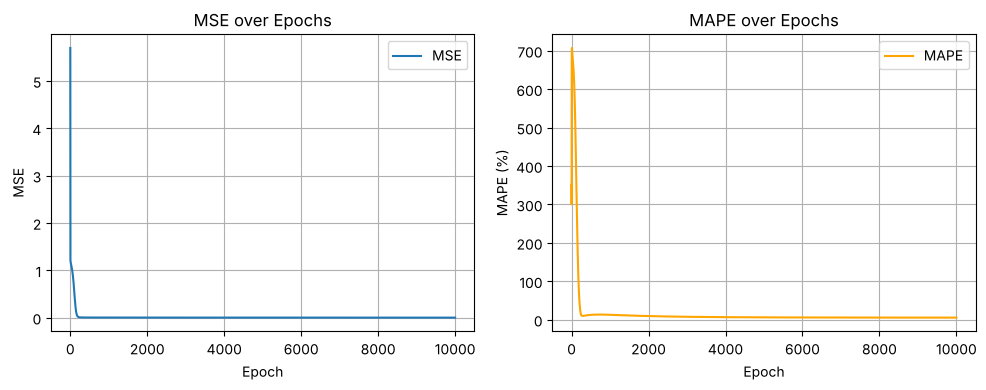

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid 함수 및 도함수
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

# 비용 함수
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# y가 0에 가까운 샘플에서는 MAPE가 크게 부풀려짐
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100

np.random.seed(0)
samples = 1000

x1 = np.random.uniform(0, 1, samples)
x2 = np.random.uniform(0, 1, samples)

X = np.column_stack((x1, x2))

y = 2 * x1 + 3 * x2 - 1
y = y.reshape(-1, 1)  # (1000, 1)

input_size = 2      # x1, x2
hidden_size = 3     # h1, h2, h3
output_size = 1     # y_hat

# 가중치 및 편향 초기화
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# 하이퍼파라미터
learning_rate = 0.3
epochs = 10000

# 손실 기록용 리스트
mse_history = []
mape_history = []

for epoch in range(epochs):
    # 순전파
    z1 = X.dot(W1) + b1
    h = sigmoid(z1)
    z2 = h.dot(W2) + b2
    y_hat = z2  # 회귀 문제이므로 출력층은 선형(항등) 활성화

    # 손실 계산
    loss_mse = mse(y, y_hat)
    loss_mape = mape(y, y_hat)
    mse_history.append(loss_mse)
    mape_history.append(loss_mape)

    # 출력층 역전파
    dz2 = (y_hat - y) / samples  # MSE 기울기 (배치 평균)
    dW2 = h.T.dot(dz2)
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # 은닉층 역전파
    dz1 = dz2.dot(W2.T) * sigmoid_derivative(z1)
    dW1 = X.T.dot(dz1)
    db1 = np.sum(dz1, axis=0, keepdims=True)

    # 파라미터 업데이트
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if epoch == 0 or (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch+1:5d} | MSE: {loss_mse:.6f} | MAPE: {loss_mape:.2f}%")

# 학습된 모델의 예측 확인
y_pred = sigmoid(X.dot(W1) + b1).dot(W2) + b2
print("\n실제값 vs 예측값 (처음 5개 샘플)")
for i in range(5):
    print(f"x1={x1[i]:.3f}, x2={x2[i]:.3f} | y={y[i, 0]:.4f} | y_hat={y_pred[i, 0]:.4f}")


plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(mse_history, label='MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('MSE over Epochs')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mape_history, label='MAPE', color='orange')
plt.xlabel('Epoch')
plt.ylabel('MAPE (%)')
plt.title('MAPE over Epochs')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

